In [10]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Математически зависимости и ограничения на модела

Таблицата съдържа подадени продуктови параметри на някои от основните продукти на What More UK Ltd. (Wham).

### 1. Капацитет и височина при еднаква основа

За идеален правоъгълен съд с постоянна **вътрешна** основа важи $V = A_{\text{вътр.}} H_{\text{вътр.}}$. Посочените външни размери не определят точно полезния капацитет заради дебелината, наклона на стените, ръбовете и формата.

При кутиите 32L, 45L и 60L отношението капацитет/външна височина е приблизително 0.178, 0.176 и 0.179 L/mm. Това е приблизителна пропорционалност, а не точна линейна зависимост. При Studio 5.01 and 5.02 височината нараства 1.875 пъти, капацитетът — около 1.917 пъти, а теглото — само около 1.355 пъти. Следователно теглото и времето за пълнене не могат да се приемат за правопропорционални на височината.

### 2. Проекционна площ и сила на затваряне

Правоъгълната оценка на площта по външните размери е:
$$A_{\text{proj}} = \frac{L W}{100}\quad [\text{cm}^2],\qquad L,W\text{ в mm}.$$

За 32L, 45L и 60L тя е 2380 cm². Това е оценка на площта, върху която въздейства налягането при щприцоване на стопеният материал, а не доказателство за еднакви матрици или еднакви изисквания към машината.

При равномерно налягане в кухината $P_{\text{cavity}}$ силата се оценява с $F = P_{\text{cavity}} A_{\text{proj}}$ в съгласувани единици (например MPa × mm² = N). Еднаква площ дава еднаква сила само при еднакво налягане и останали условия. Реалният избор на преса зависи и от броя кухини, леяковата система, запаса на безопасност, обема на впръскване и размерите на матрицата.

### 3. Дебелина и охлаждане

При еднакви материал, температурни условия и приложим модел на топлопроводност на Фурие:
$$t_c \propto \left(\frac{h}{2}\right)^2.$$

Отношението на дебелините между най-големия и най-малкия детайл (3.2 mm спрямо 1.2 mm) е около 2.67, но поради квадратичната зависимост отношението на времената за охлаждане е около 7.11 пъти. Чрез въвеждане на реалните термофизични параметри на Полипропилена (PP) — термична дифузия $\alpha = 0.082 \text{ mm}^2/\text{s}$ и специфичния температурен градиент, теоретичният модел успешно трансформира параболичната зависимост в реално време за охлаждане в секунди ($t_c$). Трябва да се има предвид обаче, че изчисленото време е теоретично минимум за втвърдяване на стената и не отчита допълнителни фактори като времето за пластификация, затваряне на пресата и динамичното топлинно съпротивление при отлепяне на детайла от матрицата.

### 4. Допуски и илюстративни нормални разпределения

Ширината на допуска е $USL-LSL$. За големите кутии тя е 5 mm, или около 0.84% от номиналните 595 mm; за Studio 4.01/4.02 е 2 mm, или около 0.78% от 255 mm.

Границите на допуска не определят реалното разпределение, средна стойност или стандартно отклонение на производството. За графиките по-долу се **приема** нормално разпределение с $\mu=(LSL+USL)/2$ и $\sigma=(USL-LSL)/6$. Така границите са на $\mu\pm3\sigma$ (около 99.73% от моделното разпределение). Това е илюстрация; за оценка на реалния процес са нужни измервания.



In [12]:
# Подадени данни за Wham (What More UK)
wham_data = {
    "Продукт (Wham Product)": [
        "Wham Crystal Box 17L",
        "Wham Crystal Box 20L",
        "Wham Crystal Box 32L",
        "Wham Crystal Box 45L",
        "Wham Crystal Box 60L",
        "Studio Basket 4.01 (Shallow)",
        "Studio Basket 4.02 (Deep)",
        "Studio Basket 5.01 (Shallow)",
        "Studio Basket 5.02 (Deep)"
    ],
    "Серия": ["Crystal", "Crystal", "Crystal", "Crystal", "Crystal", "Studio", "Studio", "Studio", "Studio"],
    "Капацитет (Литри)": [17.0, 20.0, 32.0, 45.0, 60.0, 2.0, 3.9, 6.0, 11.5],

    # Външни размери в милиметри (L x W x H)
    "Дължина L (mm)": [430.0, 390.0, 595.0, 595.0, 595.0, 255.0, 255.0, 350.0, 350.0],
    "Ширина W (mm)": [330.0, 290.0, 400.0, 400.0, 400.0, 170.0, 170.0, 260.0, 260.0],
    "Височина H (mm)": [170.0, 250.0, 180.0, 255.0, 335.0, 60.0, 110.0, 80.0, 150.0],

    # Инженерно-производствени данни за полипропиленовите детайли (PP)
    "Тегло (kg)": [0.56, 0.62, 1.05, 1.25, 1.64, 0.12, 0.26, 0.31, 0.42],
    "Дебелина на стената h (mm)": [2.2, 2.2, 2.8, 3.0, 3.2, 1.2, 1.4, 1.5, 1.6],

    # Допуски (За статистическия контрол за дължината L в mm)
    "Долна граница LSL (mm)": [428.5, 388.5, 592.5, 592.5, 592.5, 254.0, 254.0, 348.5, 348.5],
    "Горна граница USL (mm)": [431.5, 391.5, 597.5, 597.5, 597.5, 256.0, 256.0, 351.5, 351.5]
}

# Инициализиране на таблицата
df_wham = pd.DataFrame(wham_data)

# Автоматично генериране на геометричното понятие "Проекционна площ" (A = L * W), превърнато в cm²
df_wham["Проекционна площ A_proj (cm²)"] = (df_wham["Дължина L (mm)"] * df_wham["Ширина W (mm)"]) / 100

# Извеждане на пълната чиста таблица в Jupyter Notebook
df_wham

,Продукт (Wham Product),Серия,Капацитет (Литри),Дължина L (mm),Ширина W (mm),Височина H (mm),Тегло (kg),Дебелина на стената h (mm),Долна граница LSL (mm),Горна граница USL (mm),Проекционна площ A_proj (cm²)
0,Wham Crystal Box 17L,Crystal,17.0,430.0,330.0,170.0,0.56,2.2,428.5,431.5,1419.0
1,Wham Crystal Box 20L,Crystal,20.0,390.0,290.0,250.0,0.62,2.2,388.5,391.5,1131.0
2,Wham Crystal Box 32L,Crystal,32.0,595.0,400.0,180.0,1.05,2.8,592.5,597.5,2380.0
3,Wham Crystal Box 45L,Crystal,45.0,595.0,400.0,255.0,1.25,3.0,592.5,597.5,2380.0
4,Wham Crystal Box 60L,Crystal,60.0,595.0,400.0,335.0,1.64,3.2,592.5,597.5,2380.0
5,Studio Basket 4.01 (Shallow),Studio,2.0,255.0,170.0,60.0,0.12,1.2,254.0,256.0,433.5
6,Studio Basket 4.02 (Deep),Studio,3.9,255.0,170.0,110.0,0.26,1.4,254.0,256.0,433.5
7,Studio Basket 5.01 (Shallow),Studio,6.0,350.0,260.0,80.0,0.31,1.5,348.5,351.5,910.0
8,Studio Basket 5.02 (Deep),Studio,11.5,350.0,260.0,150.0,0.42,1.6,348.5,351.5,910.0


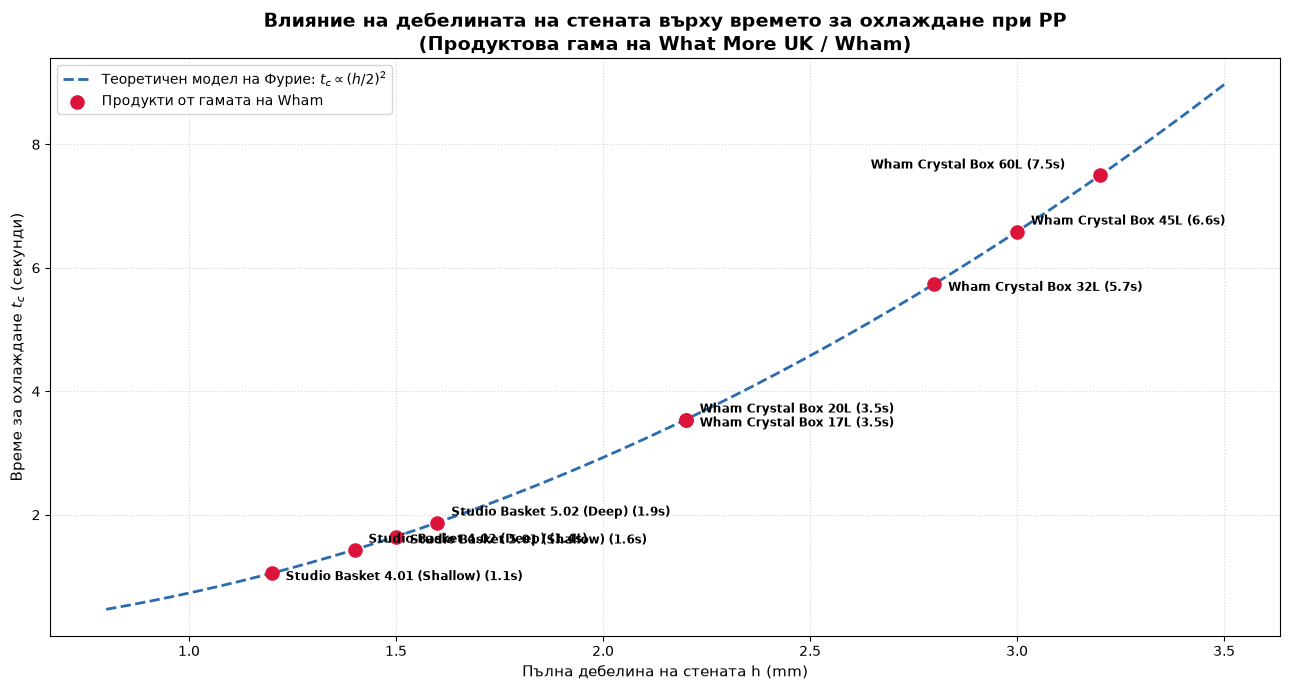

,Продукт,Дебелина h (mm),Време за охлаждане tc (сек)
5,Studio Basket 4.01 (Shallow),1.200000,1.05 сек
6,Studio Basket 4.02 (Deep),1.400000,1.43 сек
7,Studio Basket 5.01 (Shallow),1.500000,1.65 сек
8,Studio Basket 5.02 (Deep),1.600000,1.87 сек
0,Wham Crystal Box 17L,2.200000,3.54 сек
1,Wham Crystal Box 20L,2.200000,3.54 сек
2,Wham Crystal Box 32L,2.800000,5.74 сек
3,Wham Crystal Box 45L,3.000000,6.59 сек
4,Wham Crystal Box 60L,3.200000,7.50 сек


Отношение на максималното към минималното време за охлаждане ($t_c$): 7.11 пъти


In [13]:
# 1. Термодинамични параметри за ПОЛИПРОПИЛЕН (PP) от предните клетки
T_m = 235.0    # Температура на стопилката (°C)
T_w = 25.0     # Температура на матрицата (°C)
T_e = 50.0     # Температура на изваждане (°C)
alpha = 0.082  # Термична дифузия (mm²/s)

# Изчисляване на логаритмичната константа по Фурие/Нютон
log_part = np.log((4 / np.pi) * ((T_m - T_w) / (T_e - T_w)))

# 2. Подготовка на данните от оригиналната таблица df_wham
df = df_wham[
    ["Продукт (Wham Product)", "Дебелина на стената h (mm)"]
].rename(columns={
    "Продукт (Wham Product)": "Продукт",
    "Дебелина на стената h (mm)": "Дебелина h (mm)"
}).copy()

#Изчисляваме РЕАЛНОТО време за охлаждане в секунди (с отчитане на двустранното охлаждане h/2)
df["Време за охлаждане tc (сек)"] = (((df["Дебелина h (mm)"] / 2) ** 2) / (np.pi**2 * alpha)) * log_part

# 3. Генериране на теоретичната параболична крива в секунди
h_curve = np.linspace(0.8, 3.5, 300)
cooling_curve = (((h_curve / 2) ** 2) / (np.pi**2 * alpha)) * log_part

# 4. Построяване на графиката
fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    h_curve,
    cooling_curve,
    label=r"Теоретичен модел на Фурие: $t_c \propto (h/2)^2$",
    color='#2b6cb0',
    linestyle='--',
    linewidth=2
)

# Точки за всички продукти от гамата
ax.scatter(
    df["Дебелина h (mm)"],
    df["Време за охлаждане tc (сек)"],
    color='crimson',
    s=90,
    zorder=3,
    label="Продукти от гамата на Wham"
)

# Етикети до точките с динамично изписани секунди за всеки продукт
# Списъкът с отмествания съвпада точно с броя продукти (9 кутии)
offsets = [
    (10, -5), (10, 5), (10, -5), (10, 5), (-165, 5),
    (10, -5), (10, 5), (10, -5), (10, 5)
]

for (_, row), offset in zip(df.iterrows(), offsets):
    ax.annotate(
        f"{row['Продукт']} ({row['Време за охлаждане tc (сек)']:.1f}s)",
        (row["Дебелина h (mm)"], row["Време за охлаждане tc (сек)"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=8.5,
        fontweight='bold'
    )

ax.set_title(
    "Влияние на дебелината на стената върху времето за охлаждане при PP\n(Продуктова гама на What More UK / Wham)",
    fontsize=14,
    fontweight='bold'
)
ax.set_xlabel("Пълна дебелина на стената h (mm)", fontsize=11)
ax.set_ylabel("Време за охлаждане $t_c$ (секунди)", fontsize=11)
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 5. Извеждане на форматирана таблица в Jupyter, сортирана по дебелина
display(df.sort_values("Дебелина h (mm)").style.format({"Време за охлаждане tc (сек)": "{:.2f} сек"}))

# Сравнение на най-тънкия и най-дебелия детайл
ratio = df["Време за охлаждане tc (сек)"].max() / df["Време за охлаждане tc (сек)"].min()
print(f"Отношение на максималното към минималното време за охлаждане ($t_c$): {ratio:.2f} пъти")


,Продукт (Wham Product),Дължина L (mm),Долна граница LSL (mm),Горна граница USL (mm),Допуск (mm),Допуск (%),Целева sigma (mm),Дебелина на стената h (mm),Време за охлаждане tc (сек)
0,Wham Crystal Box 17L,430.0,428.5,431.5,3.0,0.698,0.500,2.2,3.543
1,Wham Crystal Box 20L,390.0,388.5,391.5,3.0,0.769,0.500,2.2,3.543
2,Wham Crystal Box 32L,595.0,592.5,597.5,5.0,0.840,0.833,2.8,5.739
3,Wham Crystal Box 45L,595.0,592.5,597.5,5.0,0.840,0.833,3.0,6.588
4,Wham Crystal Box 60L,595.0,592.5,597.5,5.0,0.840,0.833,3.2,7.496
5,Studio Basket 4.01 (Shallow),255.0,254.0,256.0,2.0,0.784,0.333,1.2,1.054
6,Studio Basket 4.02 (Deep),255.0,254.0,256.0,2.0,0.784,0.333,1.4,1.435
7,Studio Basket 5.01 (Shallow),350.0,348.5,351.5,3.0,0.857,0.500,1.5,1.647
8,Studio Basket 5.02 (Deep),350.0,348.5,351.5,3.0,0.857,0.500,1.6,1.874


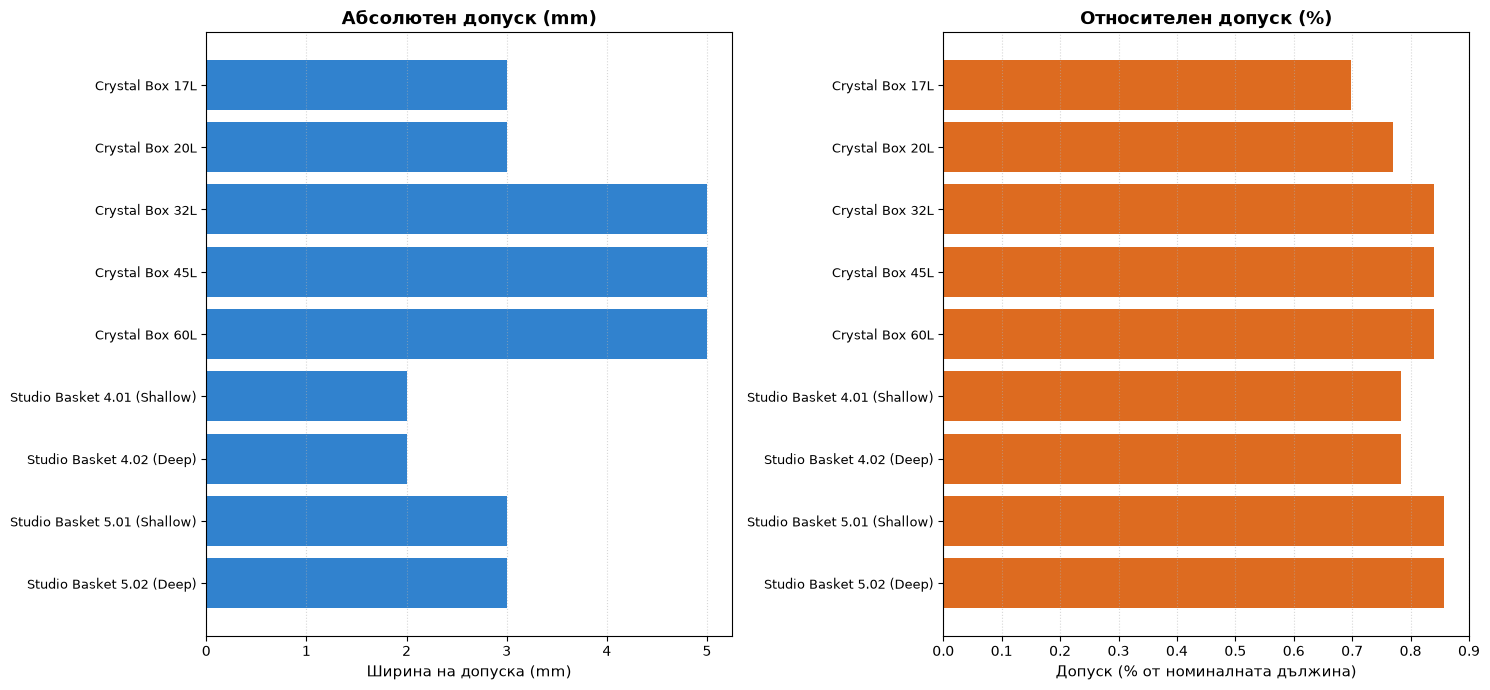

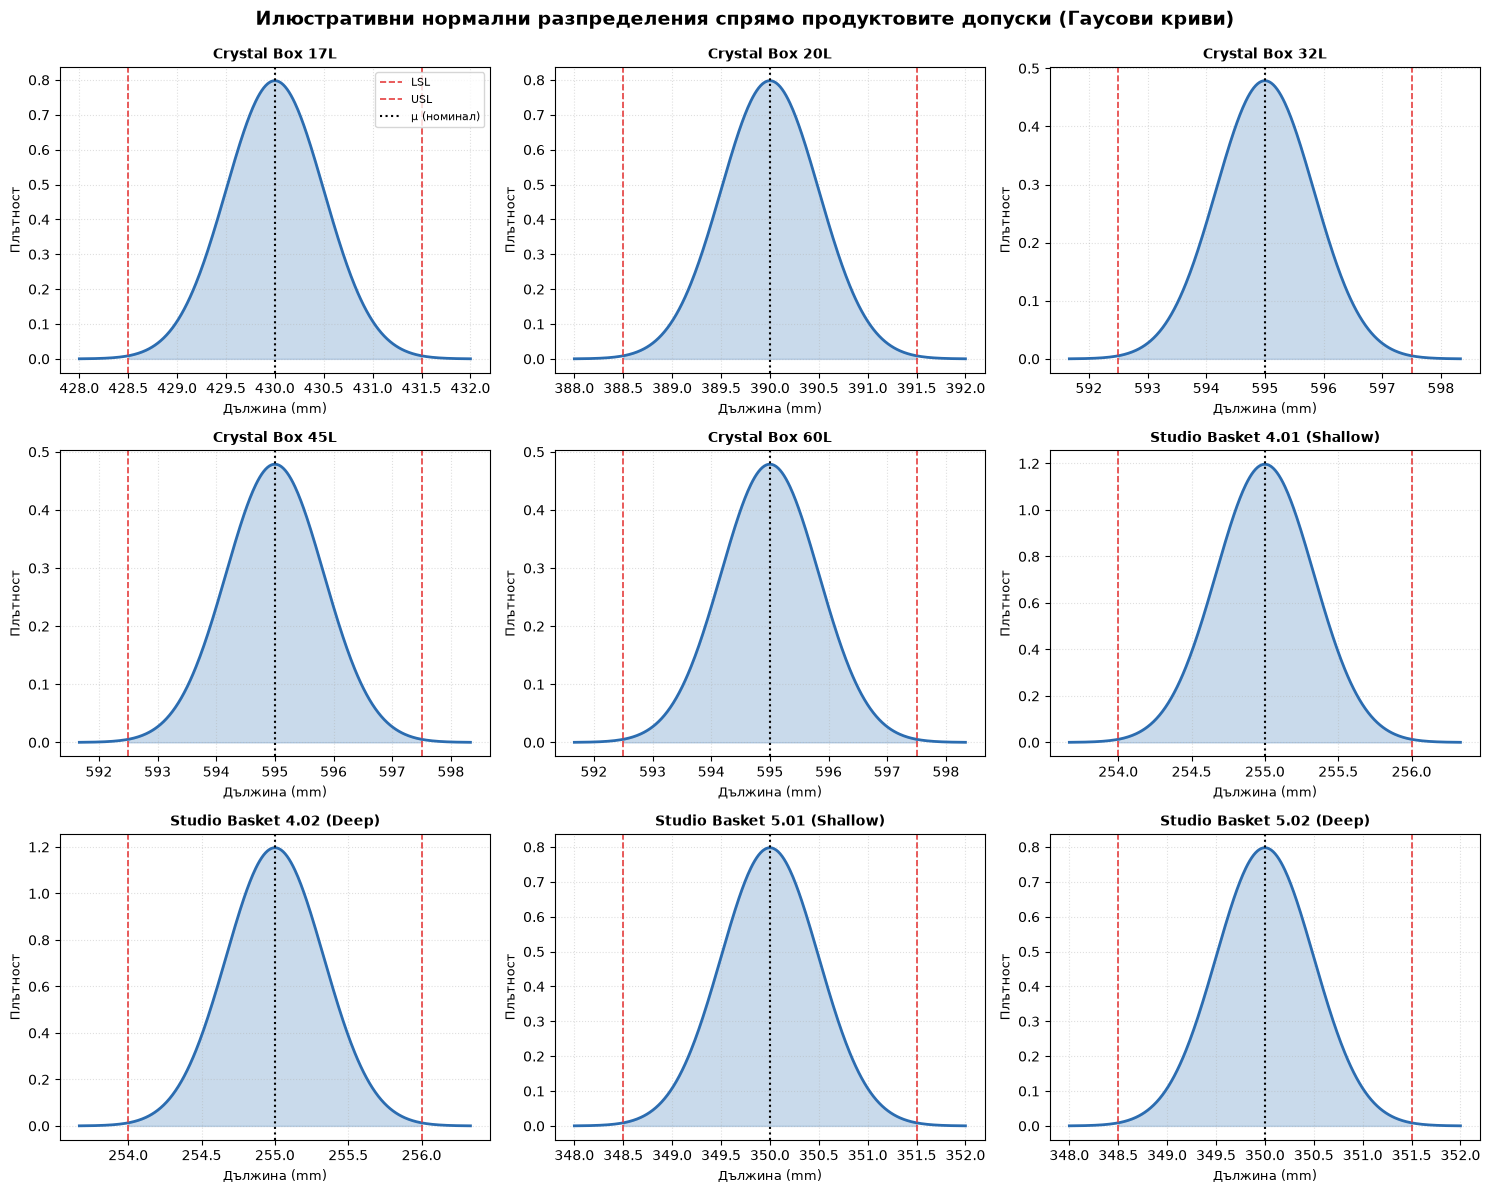

ИНЖЕНЕРНО-СТАТИСТИЧЕСКО ОБОБЩЕНИЕ НА ПРОДУКТОВАТА ГАМА
-------------------------------------------------------------------------------------
Wham Crystal Box 17L.......... Допуск: 3.0 mm ( 0.70%) | Целева σ: 0.500 mm | Охлаждане:  3.54 сек
Wham Crystal Box 20L.......... Допуск: 3.0 mm ( 0.77%) | Целева σ: 0.500 mm | Охлаждане:  3.54 сек
Wham Crystal Box 32L.......... Допуск: 5.0 mm ( 0.84%) | Целева σ: 0.833 mm | Охлаждане:  5.74 сек
Wham Crystal Box 45L.......... Допуск: 5.0 mm ( 0.84%) | Целева σ: 0.833 mm | Охлаждане:  6.59 сек
Wham Crystal Box 60L.......... Допуск: 5.0 mm ( 0.84%) | Целева σ: 0.833 mm | Охлаждане:  7.50 сек
Studio Basket 4.01 (Shallow).. Допуск: 2.0 mm ( 0.78%) | Целева σ: 0.333 mm | Охлаждане:  1.05 сек
Studio Basket 4.02 (Deep)..... Допуск: 2.0 mm ( 0.78%) | Целева σ: 0.333 mm | Охлаждане:  1.43 сек
Studio Basket 5.01 (Shallow).. Допуск: 3.0 mm ( 0.86%) | Целева σ: 0.500 mm | Охлаждане:  1.65 сек
Studio Basket 5.02 (Deep)..... Допуск: 3.0 mm ( 0.86%) | Целева σ: 

In [14]:
# СТАТИСТИЧЕСКИ ПОКАЗАТЕЛИ ЗА ДОПУСКИТЕ И ОХЛАЖДАНЕТО
df_stats = df_wham.copy()

# 1. Термодинамични изчисления за полипропилен (PP) от предните клетки
T_m = 235.0    # Температура на стопилката (°C)
T_w = 25.0     # Температура на матрицата (°C)
T_e = 50.0     # Температура на изваждане (°C)
alpha = 0.082  # Термична дифузия (mm²/s)

log_part = np.log((4 / np.pi) * ((T_m - T_w) / (T_e - T_w)))

# Изчисляваме реалното време за охлаждане в секунди (tc)
df_stats["Време за охлаждане tc (сек)"] = (((df_stats["Дебелина на стената h (mm)"] / 2) ** 2) / (np.pi**2 * alpha)) * log_part

# 2. Статистически изчисления за геометрията
# Номинална дължина: среда на границите на допуска
df_stats["Номинална дължина (mm)"] = (
    df_stats["Долна граница LSL (mm)"] + df_stats["Горна граница USL (mm)"]
) / 2

# Ширина на допуска
df_stats["Допуск (mm)"] = (
    df_stats["Горна граница USL (mm)"] - df_stats["Долна граница LSL (mm)"]
)

# Допускът като процент от номиналната дължина
df_stats["Допуск (%)"] = (
    df_stats["Допуск (mm)"] / df_stats["Номинална дължина (mm)"] * 100
)

# Илюстративно допускане за 6 sigma процеси
df_stats["Целева sigma (mm)"] = df_stats["Допуск (mm)"] / 6

# Извеждане на статистическата таблица в Jupyter
display(
    df_stats[
        [
            "Продукт (Wham Product)",
            "Дължина L (mm)",
            "Долна граница LSL (mm)",
            "Горна граница USL (mm)",
            "Допуск (mm)",
            "Допуск (%)",
            "Целева sigma (mm)",
            "Дебелина на стената h (mm)",
            "Време за охлаждане tc (сек)"
        ]
    ].round(3)
)

# 3. Графика: Допуски в милиметри и проценти
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

labels = [
    name.replace("Wham ", "")
    for name in df_stats["Продукт (Wham Product)"]
]

y = np.arange(len(df_stats))

# Лява графика: Абсолютен допуск
axes[0].barh(y, df_stats["Допуск (mm)"], color='#3182ce')
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel("Ширина на допуска (mm)", fontsize=11)
axes[0].set_title("Абсолютен допуск (mm)", fontsize=13, fontweight='bold')
axes[0].grid(axis="x", linestyle=':', alpha=0.5)

# Дясна графика: Относителен допуск
axes[1].barh(y, df_stats["Допуск (%)"], color='#dd6b20')
axes[1].set_yticks(y)
axes[1].set_yticklabels(labels, fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlabel("Допуск (% от номиналната дължина)", fontsize=11)
axes[1].set_title("Относителен допуск (%)", fontsize=13, fontweight='bold')
axes[1].grid(axis="x", linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


# 1. Гаусови криви за всички 9 продукта
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, df_stats.iterrows()):
    LSL = row["Долна граница LSL (mm)"]
    USL = row["Горна граница USL (mm)"]

    # Среда на допуска: номинална стойност за илюстрацията
    mu = (LSL + USL) / 2

    # Хипотеза: LSL и USL са на ±3 sigma
    sigma = (USL - LSL) / 6

    x = np.linspace(
        mu - 4 * sigma,
        mu + 4 * sigma,
        400
    )

    # Плътност на нормалното разпределение
    pdf = (
        1 / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    )

    ax.plot(x, pdf, color='#2b6cb0', linewidth=2)
    ax.fill_between(
        x, pdf,
        where=(x >= LSL) & (x <= USL),
        color='#2b6cb0',
        alpha=0.25
    )

    ax.axvline(LSL, color='#e53e3e', linestyle="--", linewidth=1.2, label="LSL")
    ax.axvline(USL, color='#e53e3e', linestyle="--", linewidth=1.2, label="USL")
    ax.axvline(mu, color='black', linestyle=":", linewidth=1.5, label="μ (номинал)")

    ax.set_title(
        row["Продукт (Wham Product)"].replace("Wham ", ""),
        fontsize=10,
        fontweight='bold'
    )
    ax.set_xlabel("Дължина (mm)", fontsize=9)
    ax.set_ylabel("Плътност", fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.4)

# Поставяне на обща легенда само на първия субплот, за да не се дублира
axes[0].legend(fontsize=8, loc='upper right')

fig.suptitle(
    "Илюстративни нормални разпределения спрямо продуктовите допуски (Гаусови криви)",
    fontsize=14,
    fontweight='bold',
    y=0.99
)
plt.tight_layout()
plt.show()

# 2. Инженерно-статистично обобщение
print("ИНЖЕНЕРНО-СТАТИСТИЧЕСКО ОБОБЩЕНИЕ НА ПРОДУКТОВАТА ГАМА")
print("-" * 85)

for _, row in df_stats.iterrows():
    print(
        f"{row['Продукт (Wham Product)']:.<30} "
        f"Допуск: {row['Допуск (mm)']:>3.1f} mm ({row['Допуск (%)']:>5.2f}%) | "
        f"Целева σ: {row['Целева sigma (mm)']:.3f} mm | "
        f"Охлаждане: {row['Време за охлаждане tc (сек)']:>5.2f} сек"
    )


### Абсолютен и относителен допуск (Хоризонталните стълбовидни графики)
Тези две графики анализират геометрията на конструктивните изисквания за точност при изработката на дължината ($L$) на детайлите.

* **Лява графика (Абсолютен допуск в mm):** Показва физическия прозорец за допустима производствена грешка ($USL - LSL$). Малките кошници Studio имат тесен допуск ($2\text{ mm}$), докато големите кутии Crystal Box имат по-широк такъв ($5\text{ mm}$). Това е обосновано от факта, че по-големите обемни детайли претърпяват много по-голямо и трудно за контролиране обемно свиване при кристализацията на PP.
* **Дясна графика (Относителен допуск в %):** Превръща абсолютните милиметри в процент от номиналната дължина на кутията. Анализът разкрива, че **в процентно отношение изискването за точност към процеса е почти константно – между 0.78% и 0.84%** за цялата продуктова гама. Това доказва, че въпреки различните размери, производствената технология поддържа сходно високо ниво на прецизност.

### Гаусови криви на допуските (Мрежа от 3х3 разпределения)
Тези графики пренасят геометричните параметри в полето на математическата статистика и управлението на качеството чрез концепцията за Шест Сигма ($6\sigma$). Тъй като липсват реални емпирични измервания от линията, тук е симулиран **стабилен и центриран идеален процес**.

* **Синята камбановидна крива (Плътност на вероятността - PDF):** Показва вероятностното разпределение на дължината на произведените кутии. Върхът на камбаната съвпада с математическото очакване ($\mu$), което е точно средата на инженерния допуск (номиналния размер). Там процесът е най-стабилен и вероятността за производство на детайли с тези размери е най-висока.
* **Червените прекъснати линии (LSL и USL):** Инженерните граници за качество:
    * $LSL$ (*Lower Specification Limit*) – минимално допустима дължина.
    * $USL$ (*Upper Specification Limit*) – максимално допустима дължина.
* **Защрихованата зона ($\pm3\sigma$):** Съгласно заложената хипотеза, че обхватът на допуска е равен на $6\sigma$, защрихованата площ покрива точно три стандартни отклонения вляво и вдясно от средата. Математически това гарантира, че **99.73% от всички произведени кутии Wham ще бъдат напълно годни** и ще съответстват на спецификацията. Извън червените линии остават едва 0.27% потенциален производствен брак.
